# Search: Solving a Maze Using a Goal-based Agent

Student Name: Bùi Anh Đức

I have used the following AI tools: Chat GPT

I understand that my submission needs to be my own work: Đức

## Learning Outcomes

* Formulate search problems using key components like initial state, actions, and goal state in a deterministic, fully observable environment.
* Implement and compare search algorithms including BFS, DFS, GBFS, A*, and IDS for planning paths through mazes.
* Analyze algorithm performance by measuring path cost, node expansions, depth, and memory usage across various maze types.
* Use visualization tools to represent maze paths and support debugging and analysis.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the notebook file and the completely rendered notebook with all outputs as a HTML file. 


## Introduction

In this exercise, we will implement the planning function for a type of goal-based agent called a __planning agent__. The planning function uses a map it is given to plan a path through the maze from the starting location $S$ to the goal location $G$. We will only focus on the planning function, so you do not need to implement an environment, just use the map to search for a path to solve the maze. 

Once the plan is made, the agent in a deterministic environment (i.e., the transition function is deterministic with the outcome of each state/action pair fixed and no randomness) can just follow the plan step-by-step and does not need to care about the percepts.
This is also called an **[open-loop system](https://en.wikipedia.org/wiki/Open-loop_controller).**
The execution phase is trivial and can be executed using a model-based reflex agent 
that ignores all percepts and just follows the plan. I will show you a short example, but you do not implement it in this exercise.

Given that the agent has a complete and correct map, the environment is **fully observable, discrete, deterministic, and known.** 
Remember:

* **Fully observable** means that the agent can see its state and what the available actions are. That means the **percepts contain the complete current state.**
Here, during planning, the agent always sees its x and y coordinates on the map and
also seeks when it has reached the goal state. 
* **Discrete** means that we have a **finite set of states.** The maze has a finite set 
of squares the agent can be in.
* **Deterministic** means that the **transition function contains no randomness.** An action in a state will always produce the same result. Going south from the start state always will lead to the same square.
* **Know** means that the agent **knows the complete transition function.** The 
agent has the map and therefore knows how its position changes when it walks in a direction.

Tree search algorithm implementations that you find online typically come from data structures courses and have a different aim than AI tree search. These algorithms assume that you already have a tree in memory. We are interested in dynamically creating a search tree with the aim of finding a good/the best path from the root note to the goal state. Follow the pseudo code presented in the text book (and replicated in the slides) closely. Ideally, we would like to search only a small part of the maze, i.e., create a search tree with as few nodes as possible. 

Several mazes for this exercise are stored as text files. We need to make sure that they are locally available.

In [2]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

In [3]:
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

base_url = "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Search/"
download("maze_helper.py", base_url)

mazes = ["small_maze.txt", "medium_maze.txt", "large_maze.txt", "L_maze.txt", "empty_maze.txt", "empty_maze_2.txt", "loops_maze.txt", "open_maze.txt", ]
for maze in mazes:
    download(maze, base_url)

Here is the small example maze:

In [4]:
with open("small_maze.txt", "r") as f:
    maze_str = f.read()
print(maze_str)

XXXXXXXXXXXXXXXXXXXXXX
X XX        X X      X
X    XXXXXX X XXXXXX X
XXXXXX     S  X      X
X    X XXXXXX XX XXXXX
X XXXX X         X   X
X        XXX XXX   X X
XXXXXXXXXX    XXXXXX X
XG         XX        X
XXXXXXXXXXXXXXXXXXXXXX



**Note:** If you get an error here that the file cannot be found, then you need to download it. See [HOWTO Work on Assignments.](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/working_on_assignments.md)

## Parsing and pretty printing the maze

The maze can also be displayed in color using code in the module [maze_helper.py](maze_helper.py). The code parses the string representing the maze and converts it into a `numpy` 2d array which you can use in your implementation. Position are represented as a 2-tuple of the form `(row, col)`. 

In [5]:
import maze_helper as mh

maze = mh.parse_maze(maze_str)

# look at a position in the maze by subsetting the 2d array
print("Position(0,0):", maze[0, 0])

# there is also a helper function called `look(maze, pos)` available
# which uses a 2-tuple for the position.
print("Position(8,1):", mh.look(maze, (8, 1)))

Position(0,0): X
Position(8,1): G


A helper function to visualize the maze is also available.

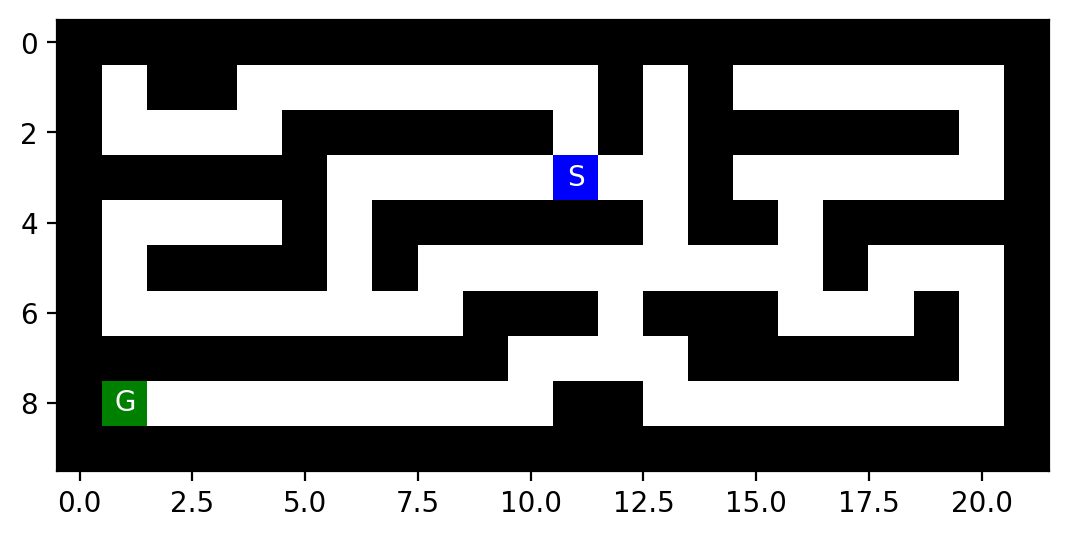

In [6]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
# use higher resolution images in notebooks

mh.show_maze(maze)

Find the `(x,y)` position of the start and the goal using the helper function `find_pos()`

In [7]:
print("Start location:", mh.find_pos(maze, what = "S"))
print("Goal location:", mh.find_pos(maze, what = "G"))

Start location: (np.int64(3), np.int64(11))
Goal location: (np.int64(8), np.int64(1))


Helper function documentation.

In [8]:
help(mh)

Help on module maze_helper:

NAME
    maze_helper

DESCRIPTION
    Code for the Maze Assignment by Michael Hahsler
    Usage:
        import maze_helper as mh
        mh.show_some_mazes()

FUNCTIONS
    animate_maze(result, repeat=False)
        (Experimental) Build an animation from a list of mazes.

        Parameters:
            result: a list with the elements path, reached, actions and maze_anim with a list of maze arrays that contain what you want to visualize.
            repeat: if True, the animation will repeat.

    find_pos(maze, what='S')
        Find start/goal in a maze and returns the first one.
        Caution: there is no error checking!

        Parameters:
            maze: a array with characters produced by parse_maze()
            what: the letter to be found ('S' for start and 'G' for goal)

        Returns:
            a tupple (x, y) for the found position.

    look(maze, pos)
        Look at the label of a square with the position as an array of the form (x

You will need to make a local copy of the module file [maze_helper.py](maze_helper.py) in the same folder where your notebook is.

## An Example for a Planning Agent

I will show you here how to implement a simple agent that uses a random plan. It will not solve the maze, but show you how the mechanics work.

First, we define a generic planning agent that fist plans, and then executes the plan step-by-step. 

In [9]:
class Planning_Agent:
    def __init__(self, maze, start, goal, planning_function):
        self.maze = maze
        self.start = start
        self.goal = goal
        self.planning_function = planning_function
        self.plan = None
        self.progress = None

    def act(self):
        # plan if no plan exists
        if self.plan is None:
            print("Planning...")
            self.plan = self.planning_function(self.maze, self.start, self.goal)
            self.progress = 0
        
        # check if plan is completed
        if self.progress >= len(self.plan):        
            raise Exception("Completed Plan. No more planned actions")
        
        # follow the plan
        action = self.plan[self.progress]
        print(f"Following plan... step {self.progress}: {action}")

        self.progress += 1
        return action

Next, we define the planning function. This function is what you will implement in this assignment.  

In [10]:
import numpy as np

def plan_random(maze, start, goal):
    """Create a random plan with 10 steps"""
    plan = np.random.choice(["N", "E", "S", "W"], size=10, replace=True).tolist()
    return plan

plan_random(maze, (1,1), (8,8))

['N', 'N', 'N', 'S', 'W', 'W', 'S', 'W', 'S', 'E']

This planning function is not great and will not produce a plan that solves the maze. Your planning functions will do better.

Finally, we can create the planning agent, give it the planning function and implement a simple environment that asks it 11 times for an action.

In [11]:
my_agent = Planning_Agent(maze, mh.find_pos(maze, what = "S"), mh.find_pos(maze, what = "G"), plan_random)

def environment(agent_function, steps):
    for _ in range(steps):
        try:
            agent_function()
        except Exception as e:
            print(f"Agent exception: {e}")

environment(my_agent.act, steps=11)

Planning...
Following plan... step 0: E
Following plan... step 1: S
Following plan... step 2: E
Following plan... step 3: N
Following plan... step 4: N
Following plan... step 5: N
Following plan... step 6: N
Following plan... step 7: S
Following plan... step 8: W
Following plan... step 9: W
Agent exception: Completed Plan. No more planned actions


Note: The agent and environment implementation above is just an illustration. You will only implement and experiment with different versions of the planning function.

## Tree structure

To use tree search, you will need to implement a tree data structure in Python. 
Here is an implementation of the basic node structure for the search algorithms (see Fig 3.7 on page 73). I have added a method that extracts the path from the root node to the current node. It can be used to get the path when the search is completed.

In [12]:
class Node:
    def __init__(self, pos, parent, action, cost):
        self.pos = tuple(pos)    # the state; positions are (row,col)
        self.parent = parent     # reference to parent node. None means root node.
        self.action = action     # action used in the transition function (root node has None)
        self.cost = cost         # for uniform cost this is the depth. It is also g(n) for A* search

    def __str__(self):
        return f"Node - pos = {self.pos}; action = {self.action}; cost = {self.cost}"
    
    def get_path_from_root(self):
        """returns nodes on the path from the root to the current node."""
        node = self
        path = [node]
    
        while not node.parent is None:
            node = node.parent
            path.append(node)
        
        path.reverse()
        
        return(path)

If needed, then you can add more fields to the class like the heuristic value $h(n)$ or $f(n)$.

Examples for how to create and use a tree and information on memory management can be found [here](../HOWTOs/trees.ipynb).

# Tasks

The goal is to:

1. Implement the following search algorithms for solving different mazes:

    - Breadth-first search (BFS)
    - Depth-first search (DFS)
    - Greedy best-first search (GBFS)
    - A* search

2. Run each of the above algorithms on the 
    - [small maze](small_maze.txt), 
    - [medium maze](medium_maze.txt), 
    - [large maze](large_maze.txt), 
    - [open maze](open_maze.txt),
    - [L maze](L_maze.txt),
    - [loops maze](loops_maze.txt),
    - [empty maze](empty_maze.txt), and
    - [empty maze (rotated)](empty_maze_2.txt).
    
3. For each problem instance and each search algorithm, report the following in a table:

    - The solution and its path cost
    - Total number of nodes expanded
    - Maximum tree depth
    - Maximum size of the frontier

4. Display each solution by marking every maze square (or state) visited and the squares on the final path.

## General [10 Points]

1. Make sure that you use the latest version of this notebook.
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Defining the search problem and determining the problem size [10 Points]

Define the components of the search problem:

* Initial state
* Actions
* Transition model
* Goal state
* Path cost

Use verbal descriptions, variables and equations as appropriate. 

*Note:* You can switch the next block from code to Markdown and use formatting.

In [13]:
# Initial state: cell marked S, represented by (row, column).
# Actions: N, E, S, W when the neighboring cell is inside the grid and not a wall.
# Transition model: apply the action's row/column offset to the current position.
# Goal test: current position equals the cell marked G.
# Path cost: each move costs 1; a path of k moves has cost k.


Give some estimates for the problem size:

* $n$: state space size
* $d$: depth of the optimal solution
* $m$: maximum depth of tree
* $b$: maximum branching factor

Describe how you would determine these values for a given maze.

In [13]:
# n: number of traversable cells (an upper bound is rows * columns).
# d: optimal solution depth, found by BFS; it equals the number of moves in its path.
# m: maximum tree depth; with path-cycle checking it is at most n-1, otherwise cycles
#    can make the search tree arbitrarily deep.
# b: maximum branching factor, at most 4 in a four-direction grid.
rows, cols = maze.shape
n_states = int(np.count_nonzero(maze != 'X'))
print(f"Grid={rows}x{cols}; traversable states n={n_states}; branching factor b <= 4")


Grid=10x22; traversable states n=94; branching factor b <= 4


## Task 2: Uninformed search: Breadth-first and depth-first [40 Points]

Implement these search strategies. Follow the pseudocode in the textbook/slides. You can use the tree structure shown above to extract the final path from your solution.

Read the following **important notes** carefully:
* You can find maze solving implementations online that use the map to store information. While this is an effective idea for this two-dimensional navigation problem, it typically cannot be used for other search problems. Therefore, follow the textbook and **do not store information in the map.** Only store information in the tree created during search, and use the `reached` and `frontier` data structures where appropriate.
* DSF behavior can be implemented using the BFS tree search algorithm and simply changing the order in which the frontier is expanded (this is equivalent to best-first search with path length as the criterion to expand the next node). However, this would be a big mistake since it combines the bad space complexity of BFS with the bad time complexity of DFS! **To take advantage of the significantly smaller memory footprint of DFS, you need to implement DFS in a different way without a `reached` data structure (often also called `visited` or `explored`) and by releasing the memory for nodes that are not needed anymore.**
* Since the proper implementation of DFS does not use a `reached` data structure, redundant path checking abilities are limited to cycle checking. 
You need to implement **cycle checking since DSF is incomplete (produces an infinite loop) if cycles cannot be prevented.** You will see in your experiments that cycle checking in open spaces is challenging.

In [14]:
from collections import deque
import heapq, itertools, math
import numpy as np

DIRECTIONS = [('N', (-1, 0)), ('E', (0, 1)), ('S', (1, 0)), ('W', (0, -1))]

def _positions(maze):
    start, goal = mh.find_pos(maze, what='S'), mh.find_pos(maze, what='G')
    if start is None or goal is None:
        raise ValueError("Maze must contain S and G")
    return tuple(start), tuple(goal)

def _neighbors(maze, pos):
    rows, cols = maze.shape
    for action, (dr, dc) in DIRECTIONS:
        nxt = (pos[0] + dr, pos[1] + dc)
        if 0 <= nxt[0] < rows and 0 <= nxt[1] < cols and maze[nxt] != 'X':
            yield nxt, action

def _make_result(node, expanded_states, expanded, max_depth, max_memory, max_frontier):
    path, actions, cur = [], [], node
    while cur is not None:
        path.append(cur['state'])
        if cur['action'] is not None: actions.append(cur['action'])
        cur = cur['parent']
    path.reverse(); actions.reverse()
    return {'path': path, 'actions': actions, 'path_cost': len(actions),
            'reached': set(expanded_states), 'expanded': expanded,
            'max_depth': max_depth, 'max_memory': max_memory,
            'max_frontier': max_frontier}

def _failure(expanded_states, expanded, max_depth, max_memory, max_frontier):
    return {'path': None, 'actions': [], 'path_cost': None,
            'reached': set(expanded_states), 'expanded': expanded,
            'max_depth': max_depth, 'max_memory': max_memory,
            'max_frontier': max_frontier}

def BFS(maze):
    start, goal = _positions(maze)
    root = {'state': start, 'parent': None, 'action': None, 'depth': 0}
    frontier, reached, expanded_states = deque([root]), {start}, set()
    expanded, max_depth, max_memory, max_frontier = 0, 0, 1, 1
    while frontier:
        node = frontier.popleft()
        expanded += 1; expanded_states.add(node['state'])
        max_depth = max(max_depth, node['depth'])
        if node['state'] == goal:
            return _make_result(node, expanded_states, expanded, max_depth, max_memory, max_frontier)
        for nxt, action in _neighbors(maze, node['state']):
            if nxt not in reached:
                reached.add(nxt)
                frontier.append({'state': nxt, 'parent': node, 'action': action, 'depth': node['depth']+1})
        max_frontier = max(max_frontier, len(frontier))
        max_memory = max(max_memory, len(frontier) + len(reached))
    return _failure(expanded_states, expanded, max_depth, max_memory, max_frontier)

def DFS(maze, check_cycle=True, max_expansions=200000):
    start, goal = _positions(maze)
    root = {'state': start, 'parent': None, 'action': None, 'depth': 0}
    frontier, expanded_states = [root], set()
    expanded, max_depth, max_memory, max_frontier = 0, 0, 1, 1
    while frontier and expanded < max_expansions:
        node = frontier.pop()
        expanded += 1; expanded_states.add(node['state'])
        max_depth = max(max_depth, node['depth'])
        if node['state'] == goal:
            return _make_result(node, expanded_states, expanded, max_depth, max_memory, max_frontier)
        on_path = set()
        if check_cycle:
            cur = node
            while cur is not None:
                on_path.add(cur['state']); cur = cur['parent']
        for nxt, action in _neighbors(maze, node['state']):
            if not check_cycle or nxt not in on_path:
                frontier.append({'state': nxt, 'parent': node, 'action': action, 'depth': node['depth']+1})
        max_frontier = max(max_frontier, len(frontier))
        max_memory = max(max_memory, len(frontier) + node['depth'] + 1)
    return _failure(expanded_states, expanded, max_depth, max_memory, max_frontier)

def manhattan(pos, goal):
    return abs(pos[0]-goal[0]) + abs(pos[1]-goal[1])

def informed_search(maze, strategy='GBFS'):
    start, goal = _positions(maze)
    counter = itertools.count()
    root = {'state': start, 'parent': None, 'action': None, 'depth': 0, 'g': 0}
    def priority(node):
        h = manhattan(node['state'], goal)
        return h if strategy == 'GBFS' else node['g'] + h
    frontier = [(priority(root), next(counter), root)]
    best_g, expanded_states = {start: 0}, set()
    expanded, max_depth, max_memory, max_frontier = 0, 0, 1, 1
    while frontier:
        _, _, node = heapq.heappop(frontier)
        state = node['state']
        if node['g'] != best_g.get(state): continue
        expanded += 1; expanded_states.add(state)
        max_depth = max(max_depth, node['depth'])
        if state == goal:
            return _make_result(node, expanded_states, expanded, max_depth, max_memory, max_frontier)
        for nxt, action in _neighbors(maze, state):
            new_g = node['g'] + 1
            if new_g < best_g.get(nxt, math.inf):
                best_g[nxt] = new_g
                child = {'state': nxt, 'parent': node, 'action': action,
                         'depth': node['depth']+1, 'g': new_g}
                heapq.heappush(frontier, (priority(child), next(counter), child))
        max_frontier = max(max_frontier, len(frontier))
        max_memory = max(max_memory, len(frontier) + len(best_g))
    return _failure(expanded_states, expanded, max_depth, max_memory, max_frontier)

def GBFS(maze): return informed_search(maze, 'GBFS')
def A_star(maze): return informed_search(maze, 'A*')

def display_solution(maze, result):
    shown = np.array(maze, dtype='<U1', copy=True)
    for pos in result['reached']:
        if shown[pos] not in ('S', 'G', 'X'): shown[pos] = '.'
    if result['path'] is not None:
        for pos in result['path']:
            if shown[pos] not in ('S', 'G', 'X'): shown[pos] = 'P'
    print("cost:", result['path_cost'], "| expanded:", result['expanded'],
          "| max depth:", result['max_depth'], "| max memory:", result['max_memory'],
          "| max frontier:", result['max_frontier'])
    mh.show_maze(shown)


How does BFS and DFS (without a reached data structure) deal with loops (cycles)?

In [16]:
# BFS graph search records each discovered state in `reached`, so a loop cannot
# enqueue the same state repeatedly. DFS deliberately has no global reached set:
# it checks only the current root-to-node path and refuses to revisit a state on
# that path. This prevents infinite loops within a branch, but different branches
# can still revisit the same state and cause repeated work.


Are your implementations complete and optimal? Explain why. What is the time and space complexity of each of **your** implementations? Especially discuss the difference in space complexity between BFS and DFS.

In [17]:
# BFS is complete on a finite maze and optimal when every move has equal cost.
# Its time and space are O(b^d) in the usual tree-search analysis; graph-search
# storage is O(n) for states/frontier on a finite grid.
# DFS with path-cycle checking is complete on a finite graph when allowed to finish,
# but can repeat states across branches; its worst-case time is exponential
# (O(b^m)). Its active stack/path memory is much smaller than BFS in typical cases,
# roughly O(bm) for the frontier plus the current path. The expansion cap in this
# implementation makes runtime bounded, so a capped run may return no solution.


## Task 3: Informed search: Implement greedy best-first search and A* search  [20 Points]

You can use the map to estimate the distance from your current position to the goal using the Manhattan distance (see https://en.wikipedia.org/wiki/Taxicab_geometry) as a heuristic function. Both algorithms are based on Best-First search which requires only a small change from the BFS algorithm you have already implemented (see textbook/slides). 

In [18]:
# GBFS selects the frontier node with minimum h(n) = Manhattan distance to G.
# A* selects minimum f(n) = g(n) + h(n), where g is the cost so far.
# Manhattan distance is admissible and consistent for four-direction unit-cost moves.


Are your implementations complete and optimal? What is the time and space complexity?

In [19]:
# GBFS is not generally optimal: it considers only estimated distance to the goal,
# and may take a longer route. On a finite maze, graph-based GBFS is complete here
# because better-cost states are tracked and each state has finite neighbors.
# A* with this admissible, consistent heuristic and unit step costs is complete and
# optimal. Both informed searches have worst-case exponential time and space in
# search depth (often described as O(b^d)); on a finite grid, stored states are O(n).


## Task 4: Comparison and discussion [20 Points] 

Run experiments to compare the implemented algorithms.

How to deal with issues:

* Your implementation returns unexpected results: Try to debug and fix the code. Visualizing the maze, the current path and the frontier after every step is very helpful. If the code still does not work, then mark the result with an asterisk (*) and describe the issue below the table.

* Your implementation cannot consistently solve a specific maze and ends up in an infinite loop:
    Debug (likely your frontier and cycle checking for DFS are the issue). If it is a shortcoming of the algorithm/implementation, then put "N/A*" in the results table and describe why this is happening.

In [18]:
# Run all algorithms on maze files available beside this notebook.
# The setup cell above downloads the standard assignment mazes when internet is available.
import os, pandas as pd
maze_files = ['small_maze.txt', 'medium_maze.txt', 'large_maze.txt', 'open_maze.txt',
              'L_maze.txt', 'loops_maze.txt', 'empty_maze.txt', 'empty_maze_2.txt']
algorithms = {'BFS': BFS, 'DFS': DFS, 'GBFS': GBFS, 'A*': A_star}
records, experiment_mazes = [], {}
for filename in maze_files:
    if not os.path.exists(filename):
        print(f"Skipping {filename}: file not found (run the download/setup cell first).")
        continue
    with open(filename, encoding='utf-8') as f:
        maze_i = mh.parse_maze(f.read())
    experiment_mazes[filename] = maze_i
    for name, solver in algorithms.items():
        result = solver(maze_i)
        records.append({'maze': filename, 'algorithm': name,
                        'path_cost': result['path_cost'],
                        'nodes_expanded': result['expanded'],
                        'max_tree_depth': result['max_depth'],
                        'max_nodes_in_memory': result['max_memory'],
                        'max_frontier_size': result['max_frontier'],
                        'solved': result['path'] is not None})
results_df = pd.DataFrame(records)
display(results_df)


,maze,algorithm,path_cost,nodes_expanded,max_tree_depth,max_nodes_in_memory,max_frontier_size,solved
0,small_maze.txt,BFS,19.0,93,19,96,9,True
1,small_maze.txt,DFS,29.0,40,29,34,5,True
2,small_maze.txt,GBFS,29.0,40,29,49,5,True
3,small_maze.txt,A*,19.0,54,19,66,8,True
4,medium_maze.txt,BFS,68.0,270,68,275,9,True
5,medium_maze.txt,DFS,152.0,154,152,160,8,True
6,medium_maze.txt,GBFS,74.0,79,74,86,4,True
7,medium_maze.txt,A*,68.0,222,68,235,8,True
8,large_maze.txt,BFS,210.0,622,210,630,8,True
9,large_maze.txt,DFS,210.0,338,214,251,38,True


Complete the following table for each maze.

__Small maze__

| algorithm | path cost | # of nodes expanded | max tree depth | max # of nodes in memory | max frontier size |
|-----------|-----------|--------------------|----------------|--------------------------|-------------------|
| BFS       | 19        | 93                 | 19             | 96                       | 9                 |
| DFS       | 29        | 40                 | 29             | 34                       | 5                 |
| GBS       | 29        | 40                 | 29             | 49                       | 5                 |
| A*        | 19        | 54                 | 19             | 66                       | 8                 |

__Medium Maze__

| algorithm | path cost | # of nodes expanded | max tree depth | max # of nodes in memory | max frontier size |
|-----------|-----------|--------------------|----------------|--------------------------|-------------------|
| BFS       | 68        | 270                | 68             | 275                      | 9                 |
| DFS       | 152       | 154                | 152            | 160                      | 8                 |
| GBS       | 74        | 79                 | 74             | 86                       | 4                 |
| A*        | 68        | 222                | 68             | 235                      | 8                 |

Present the results as using charts (see [Python Code Examples/charts and tables](../HOWTOs/charts_and_tables.ipynb)). 

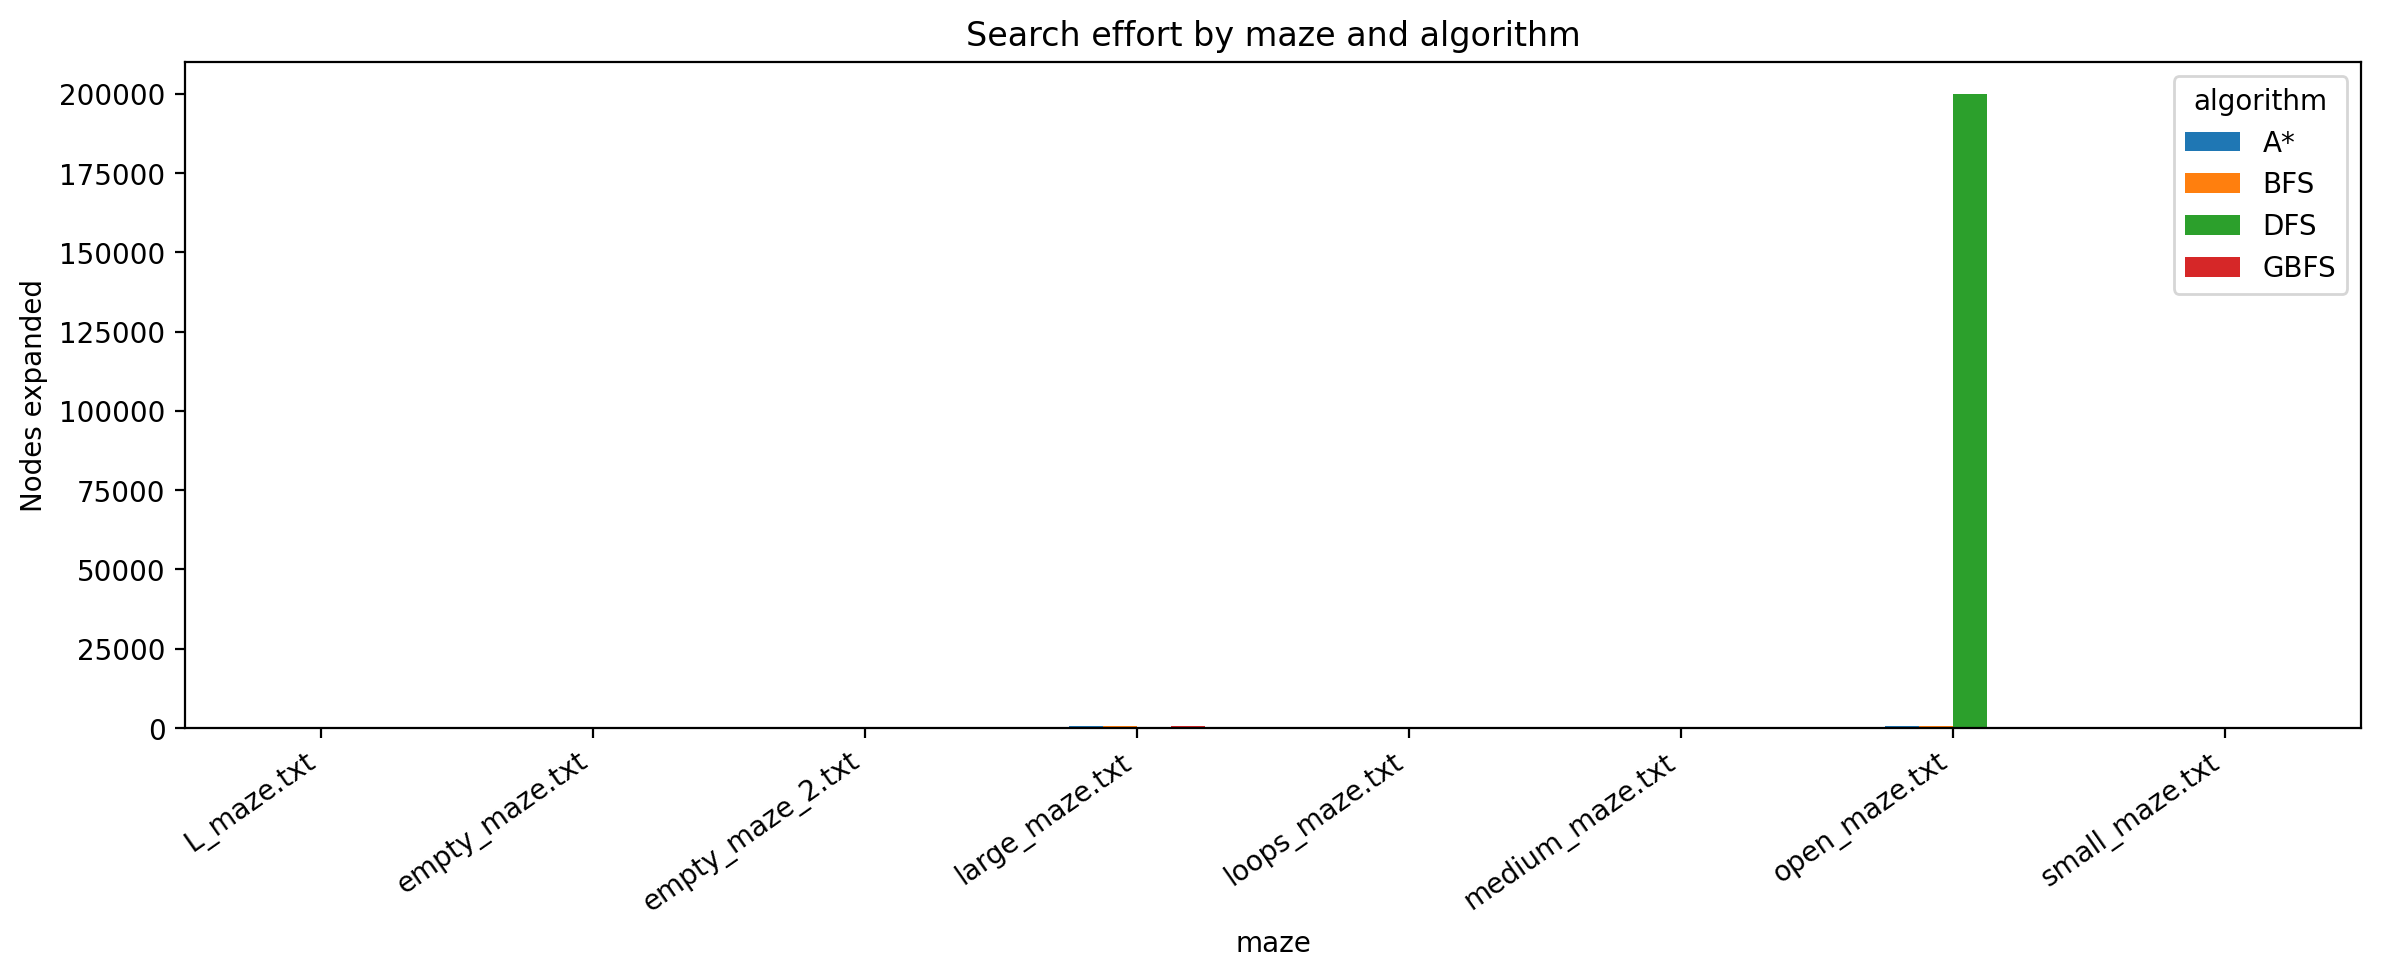

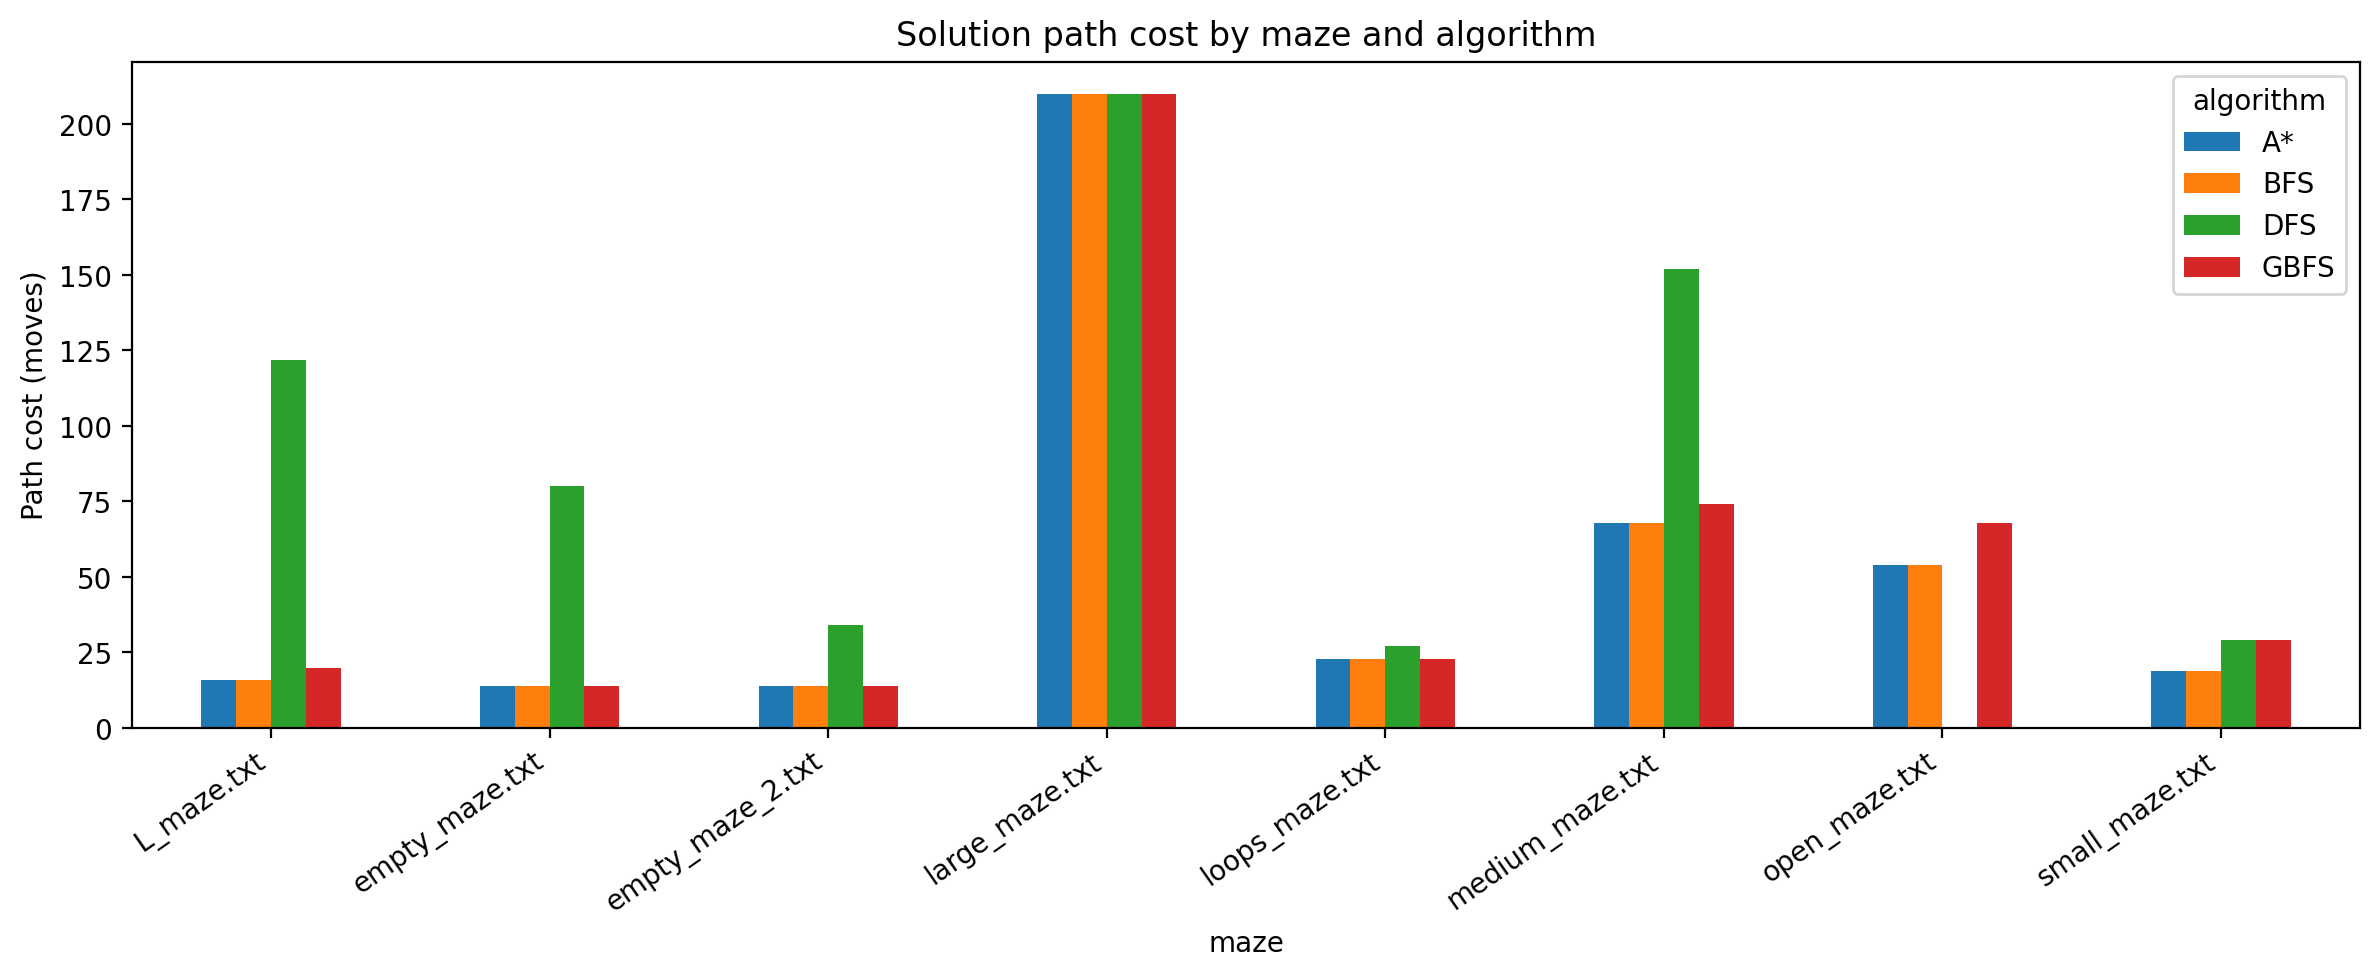

In [19]:
# Compare search effort across the mazes that were successfully loaded.
if not results_df.empty:
    import matplotlib.pyplot as plt
    ax = results_df.pivot(index='maze', columns='algorithm', values='nodes_expanded').plot(kind='bar', figsize=(12, 5))
    ax.set_ylabel('Nodes expanded'); ax.set_title('Search effort by maze and algorithm')
    plt.xticks(rotation=35, ha='right'); plt.tight_layout(); plt.show()

    ax = results_df.pivot(index='maze', columns='algorithm', values='path_cost').plot(kind='bar', figsize=(12, 5))
    ax.set_ylabel('Path cost (moves)'); ax.set_title('Solution path cost by maze and algorithm')
    plt.xticks(rotation=35, ha='right'); plt.tight_layout(); plt.show()


Discuss the most important lessons you have learned from implementing the different search strategies. 

In [20]:
# BFS reliably returns a shortest path for equal-cost actions, but may keep many
# states in memory. DFS often uses less memory, though its first solution can be
# longer and its work depends strongly on neighbor order. GBFS can expand few nodes
# when the heuristic points toward the goal, but is not guaranteed to find a shortest
# path. A* combines the cost already paid with an admissible heuristic, and therefore
# finds an optimal path while often exploring fewer states than uninformed BFS.
# Results vary with maze layout and direction ordering; use the table and charts above
# rather than assuming one algorithm always expands the fewest nodes.


## Advanced task: IDS and Multiple goals

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### IDS 
Implement IDS (iterative deepening search) using your DFS implementation. Test IDS on the mazes above. You may run into some issues with mazes with open spaces. If you cannot resolve the issues, then report and discuss what causes the problems.

In [21]:
def IDS(maze, max_expansions=200000):
    # Iterative deepening: run depth-limited DFS with limits 0, 1, 2, ...
    # Path-based cycle checking prevents loops inside each depth-limited iteration.
    start, goal = _positions(maze)
    max_limit = int(np.count_nonzero(maze != 'X'))
    total_expanded = 0
    for limit in range(max_limit + 1):
        root = {'state': start, 'parent': None, 'action': None, 'depth': 0}
        stack = [root]; iteration_count = 0
        while stack and iteration_count < max_expansions:
            node = stack.pop(); iteration_count += 1
            if node['state'] == goal:
                result = _make_result(node, set(), total_expanded + iteration_count,
                                      node['depth'], len(stack) + node['depth'] + 1, len(stack)+1)
                return result
            if node['depth'] >= limit: continue
            path_states = set(); cur = node
            while cur is not None:
                path_states.add(cur['state']); cur = cur['parent']
            for nxt, action in _neighbors(maze, node['state']):
                if nxt not in path_states:
                    stack.append({'state': nxt, 'parent': node, 'action': action,
                                  'depth': node['depth']+1})
        total_expanded += iteration_count
        if iteration_count >= max_expansions: break
    return _failure(set(), total_expanded, 0, 0, 0)

# Example IDS run on the first available maze.
if experiment_mazes:
    first_name, first_maze = next(iter(experiment_mazes.items()))
    ids_result = IDS(first_maze)
    print(first_name, "IDS path cost:", ids_result['path_cost'],
          "| expanded over iterations:", ids_result['expanded'])


small_maze.txt IDS path cost: 19 | expanded over iterations: 1056


### Multiple Goals 
Create a few mazes with multiple goals by adding one or two more goals to the medium size maze. The agent is done when it finds one of the goals.
Solve the maze with your implementations for DFS, BFS, and IDS. Run experiments to show which implementations find the optimal solution and which do not. Discuss why that is the case.

In [22]:
# Multiple-goal variant: accept any cell marked G. For demonstration, this helper
# treats all G cells as goals and otherwise uses the same neighbor rules.
def multi_goal_search(maze, strategy='BFS'):
    goals = {tuple(p) for p in np.argwhere(maze == 'G')}
    starts = np.argwhere(maze == 'S')
    if len(starts) == 0 or not goals: raise ValueError("Maze needs S and at least one G")
    start = tuple(starts[0])
    # Shared implementation for BFS/DFS/IDS, with a goal-set test.
    def depth_limited(limit=None):
        root = {'state': start, 'parent': None, 'action': None, 'depth': 0}
        frontier = deque([root]) if strategy == 'BFS' else [root]
        reached = {start} if strategy == 'BFS' else None
        expanded_states, expanded = set(), 0
        while frontier and expanded < 200000:
            node = frontier.popleft() if strategy == 'BFS' else frontier.pop()
            expanded += 1; expanded_states.add(node['state'])
            if node['state'] in goals:
                return _make_result(node, expanded_states, expanded, node['depth'], len(frontier)+node['depth']+1, len(frontier)+1)
            if limit is not None and node['depth'] >= limit: continue
            on_path=set(); cur=node
            while cur is not None: on_path.add(cur['state']); cur=cur['parent']
            for nxt, action in _neighbors(maze, node['state']):
                if strategy == 'BFS':
                    if nxt in reached: continue
                    reached.add(nxt)
                elif nxt in on_path: continue
                child={'state':nxt,'parent':node,'action':action,'depth':node['depth']+1}
                frontier.append(child)
        return _failure(expanded_states, expanded, 0, len(frontier), len(frontier))
    if strategy != 'IDS': return depth_limited()
    for depth in range(int(np.count_nonzero(maze != 'X')) + 1):
        answer=depth_limited(depth)
        if answer['path'] is not None: return answer
    return _failure(set(), 0, 0, 0, 0)

# Make a small multiple-goal example from a loaded maze by adding a second goal
# at a traversable cell. BFS is optimal; DFS may return a longer route; IDS is
# optimal for unit-cost moves when completed because it increases the depth limit.
if experiment_mazes:
    base = np.array(next(iter(experiment_mazes.values())), dtype='<U1', copy=True)
    candidates = [tuple(p) for p in np.argwhere(base == ' ') if tuple(p) != _positions(base)[0]]
    if candidates:
        base[candidates[len(candidates)//2]] = 'G'
        for method in ['BFS', 'DFS', 'IDS']:
            r = multi_goal_search(base, method)
            print(method, 'path cost:', r['path_cost'], 'expanded:', r['expanded'])


BFS path cost: 8 expanded: 35
DFS path cost: 12 expanded: 23
IDS path cost: 8 expanded: 17


## More Advanced Problems to Think About (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Intersection as States
Instead of defining each square as a state, use only intersections as states. Now the storage requirement is reduced, but the path length between two intersections can be different. If we use total path length measured as the number of squares as path cost, how can we make sure that BFS and iterative deepening search is optimal? Change the code to do so.

In [23]:
# In an unknown maze, the agent cannot plan a complete route from a map it does
# not possess. It must explore incrementally, remember observed walls/open cells,
# and replan after each observation (online search). A frontier of unexplored cells
# can guide exploration; once the goal is observed, a route can be planned through
# the discovered map. This differs from the fully observable offline setting above.


### Weighted A* search
Modify your A* search to add weights (see text book) and explore how different weights influence the result.

In [24]:
def weighted_A_star(maze, weight=1.5):
    """Weighted A*: prioritize f(n) = g(n) + weight*h(n)."""
    if weight < 0: raise ValueError("weight must be non-negative")
    start, goal = _positions(maze)
    counter = itertools.count()
    root = {'state': start, 'parent': None, 'action': None, 'depth': 0, 'g': 0}
    def score(node): return node['g'] + weight * manhattan(node['state'], goal)
    frontier = [(score(root), next(counter), root)]
    best_g, expanded_states = {start: 0}, set()
    expanded = max_depth = 0; max_frontier = max_memory = 1
    while frontier:
        _, _, node = heapq.heappop(frontier)
        if node['g'] != best_g.get(node['state']): continue
        expanded += 1; expanded_states.add(node['state'])
        max_depth = max(max_depth, node['depth'])
        if node['state'] == goal:
            return _make_result(node, expanded_states, expanded, max_depth, max_memory, max_frontier)
        for nxt, action in _neighbors(maze, node['state']):
            g = node['g'] + 1
            if g < best_g.get(nxt, math.inf):
                best_g[nxt] = g
                child = {'state': nxt, 'parent': node, 'action': action, 'depth': node['depth']+1, 'g': g}
                heapq.heappush(frontier, (score(child), next(counter), child))
        max_frontier = max(max_frontier, len(frontier))
        max_memory = max(max_memory, len(frontier)+len(best_g))
    return _failure(expanded_states, expanded, max_depth, max_memory, max_frontier)

# Larger weights emphasize proximity to the goal and often reduce expansions,
# but weighted A* is not guaranteed to return an optimal path when weight > 1.
if experiment_mazes:
    demo_maze = next(iter(experiment_mazes.values()))
    for w in [1, 1.5, 2, 3]:
        r = weighted_A_star(demo_maze, w)
        print(f"weight={w}: cost={r['path_cost']}, expanded={r['expanded']}")


weight=1: cost=19, expanded=54
weight=1.5: cost=19, expanded=54
weight=2: cost=19, expanded=56
weight=3: cost=19, expanded=57


### Unknown Maze
What happens if the agent does not know the layout of the maze in advance? This means that the agent faces an unknown environment, where it does not know the transition function. How does the environment look then (PEAS description)? How would you implement a rational agent to solve the maze? What if the agent still has a GPS device to tell the distance to the goal?

In [25]:
# For a partially observed environment, a practical agent alternates between:
# (1) observe adjacent cells, (2) update an internal map, (3) choose a reachable
# frontier cell that has not been explored, and (4) plan/replan a route to it.
# The agent should mark cells as open or blocked only after observing them, and stop
# when it observes the goal. This is an online exploration strategy rather than
# ordinary BFS/A* on a fully known maze.
